In [1]:
# Project settings and paths: config.py is in the project root (this also makes the modules in src/ importable)
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())))
import config

# Standard libraries
import numpy as np
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from functools import partial

# Specific libraries
import seaborn as sns
import plotly.express as px

# Import custom modules
import file_io as fio
import dicom_load as dcmload
import registration as reg
import temperature as temp

In [2]:
# Define directories
CALIB_DIR = config.SNR_DIR
SCAN_DIR = CALIB_DIR / "scan_data"
TEMP_DIR = CALIB_DIR / "temperature_data"
PLOT_DIR = config.RESULTS_PLOT_DIR / "snr"

if not CALIB_DIR.is_dir():
    raise NotADirectoryError(f"Expected a directory, got: {CALIB_DIR}") 
if not SCAN_DIR.is_dir():
    raise NotADirectoryError(f"{CALIB_DIR.stem} doesn't contain subdirectory named {SCAN_DIR.stem}") 
if not TEMP_DIR.is_dir():
    raise NotADirectoryError(f"{CALIB_DIR.stem} doesn't contain subdirectory named {TEMP_DIR.stem}") 

PLOT_DIR.mkdir(parents=True, exist_ok=True)

### LOAD & UNPACK

In [ ]:
# Load in data and save basic features 
dicom_fnames = fio.scrape_files(SCAN_DIR, filetype=["MRe", "dcm"])
dicom_fnames.sort(key = lambda x: dcmload.dicom_scantime(x))
print(f"The full dataset contains {len(dicom_fnames)} DICOM files")
dataset_unpacked = list(map(dcmload.process_dicom, dicom_fnames))
dataset_df = pd.DataFrame(dataset_unpacked)
print("Scans unpacked into pandas DataFrame structure")

The full dataset contains 51 DICOM files
Scans unpacked into pandas DataFrame structure


### PAIR W/ TEMP DATA

Full dataset contains 51 scans
Removing 0 scans - don't have corresponding temperature data
'Temperature trimmed' dataset contains 51 scans


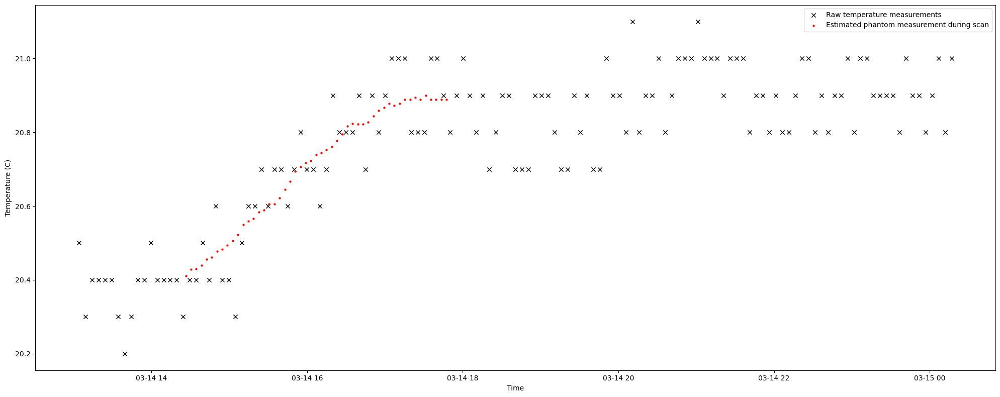

In [4]:
# Now pair scans with their temperature measurements and remove any scans without valid temperature measurements
temp_fname = TEMP_DIR / "temperatures.csv"
temp_log = np.loadtxt(temp_fname, dtype=str, delimiter=",", skiprows=1)
temp_log_dt = [[dcmload.convert_timestamp(datetime_string), float(temp)] for datetime_string, temp in temp_log]
temp_log_dt_np = np.array(temp_log_dt)

dataset_df["temperature"] = dataset_df["scan_time"].apply(partial(temp.estimate_temp, temp_log=temp_log_dt, time_window_minutes=90, f_past=0.5, n_min=None))
print(f"Full dataset contains {dataset_df.shape[0]} scans")

n_lacking_temp = np.count_nonzero(dataset_df["temperature"].isna())
print(f"Removing {n_lacking_temp} scans - don't have corresponding temperature data")

valid_df = dataset_df[dataset_df["temperature"].notna()].copy()
print(f"'Temperature trimmed' dataset contains {valid_df.shape[0]} scans")

fig, ax = plt.subplots(1, 1, figsize=(20,8))
ax.scatter(temp_log_dt_np[:,0], 
           temp_log_dt_np[:,1], 
           marker="x", 
           linewidth=1 , 
           c="k", 
           label="Raw temperature measurements")

ax.scatter(valid_df["scan_time"].values, 
           valid_df["temperature"].values, 
           marker=".", 
           linewidth=0.1, 
           c="r",
           label="Estimated phantom measurement during scan")
ax.legend()
ax.set_ylabel("Temperature (C)")
ax.set_xlabel("Time")
fig.tight_layout()
plt.show()

In [ ]:
num_repeats = valid_df.groupby("seq_name").size().rename("count").reset_index()
display(num_repeats)

,seq_name,count
0,dwi_bz_0_graddur_40,1
1,dwi_bz_800_graddur_40,50


### REGISTRATION

In [6]:
# Extract images from dataframe
# mppca_image_4d = np.stack(denoised_df["mppca_image"].values, axis=-1)
image_4d = np.stack(valid_df["image"].values, axis=-1)
aff_0 = valid_df["affine"].values[0]
spacing_0 = reg.spacing_from_affine(aff_0)

# Extract b-values in order to be able to identify b=0 scan to register other scans to
bvals = valid_df["b_value"].values

# Perform registration:
# function returns a registered 4D image array and also
# a numpy array of indices for which registration failed
reg_4d, i_drop = reg.register_to_b0(data_4d=image_4d, 
                                   bvals=bvals, 
                                   spacing=spacing_0,
                                   b0_threshold=5)

# Create a new dataframe with only the measurements that were successfully
# registered and append a column for registered scans
reg_df = valid_df.drop(index=i_drop).reset_index(drop=True)
reg_4d_reshuffled = np.transpose(reg_4d, (3,0,1,2))
reg_df["reg_image"] = list(reg_4d_reshuffled)

Registering DWI images to b=0 image: 100%|██████████| 51/51 [00:13<00:00,  3.71it/s]

Registration complete


### CREATE b=0 MASK

In [7]:
b0_threshold = 5
b0_scans = np.stack(reg_df[reg_df["b_value"] < b0_threshold]["reg_image"].values, axis=-1)
b0_avg = np.mean(b0_scans, axis=-1)
mask = reg.get_mask(b0_avg, lt_percentile=55).astype(bool)

# Plot the resulting masked data
plotdata = b0_avg
plotdata[mask==0] = 0
zmin = np.percentile(plotdata[mask], 1)
zmax = np.percentile(plotdata[mask], 99)
px.imshow(plotdata, animation_frame=2, zmin=zmin, zmax=zmax, height=800, width=1000, title="Masked b=0 image")

### SNR CALCULATION

In [8]:
b0_thresh = b0_threshold # b-value below which scans are treated as b=0

# Registered scans, as float32 arrays stacked along the first axis, [scan, x, y, z]
reg_images = np.stack(reg_df["reg_image"].values, axis=-1)
data_reshuffled = np.transpose(reg_images, [3,0,1,2]).astype(np.float32)

# Sequence parameters for each registered scan (drop the full image arrays)
snr_df = reg_df.drop(["image", "reg_image"], axis=1, inplace=False)
snr_df["image"] = list(data_reshuffled)

In [15]:
dwi_df = snr_df[snr_df["b_value"] > b0_threshold].copy()
dwi_df["adc"] = dwi_df.apply(lambda row: temp.water_diffusivity(row["temperature"]), axis=1)
adc_ref = dwi_df.iloc[0]["adc"]

dwi_df["scale_factor"] = dwi_df.apply(lambda row: np.exp(-row["b_value"] * (adc_ref - row["adc"])), axis=1)
scaled_images = dwi_df["image"].to_numpy() * dwi_df["scale_factor"].to_numpy()

signal = scaled_images.mean()
noise = scaled_images.std()
snr = signal/noise

### MEAN, STD & SNR MAPS

In [17]:
def masked_slice_animation(array, title, fname):

    # Zero everything outside the mask, then animate through axial slices
    plot_data = array.copy()
    plot_data[~mask] = 0

    zmax = plot_data[mask].max()
    zmin = plot_data[mask].min()
    fig = px.imshow(plot_data, animation_frame=2, height=800, title=title, zmin=zmin, zmax=zmax)

    # Save as a standalone interactive file (plotly.js loaded from a CDN to keep the file small)
    fig.write_html(PLOT_DIR / fname, include_plotlyjs="cdn")

    return fig

masked_slice_animation(signal, "Mean signal", "snr_mean.html")

In [18]:
masked_slice_animation(noise, "Standard deviation", "snr_std.html")

In [19]:
masked_slice_animation(snr, "SNR", "snr_map.html")

### SNR DISTRIBUTION

Average SNR: 18.2178
Fraction of voxels with SNR < 5: 0.0720
Fraction of voxels with SNR < 2: 0.0000


/var/folders/2x/cjhf7z5x01z_zb36hj149kqm0000gp/T/ipykernel_56922/228405108.py:20: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



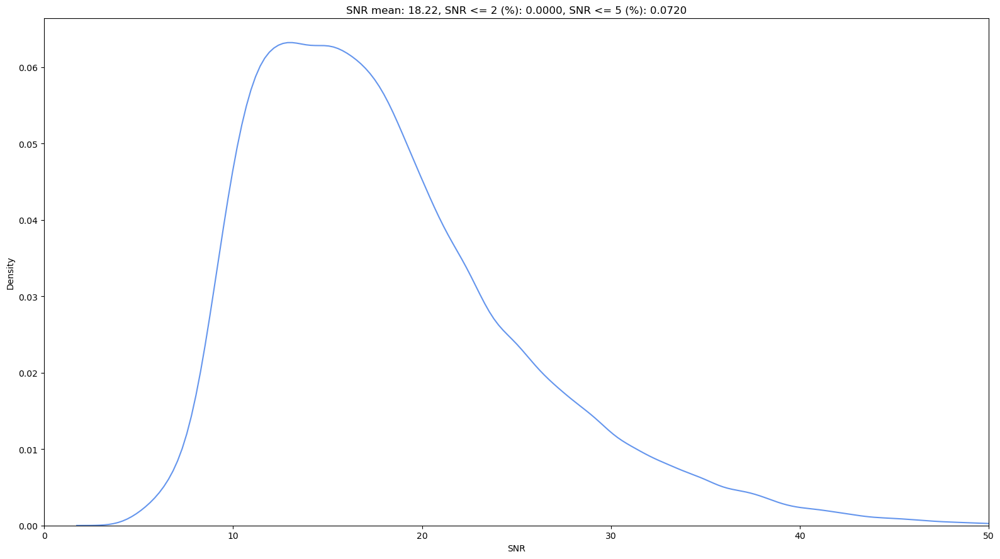

In [20]:
snr_vec = snr[mask]
n_masked = snr_vec.shape[0]
snr_2 = (np.count_nonzero(snr_vec<=2) / n_masked) * 100
snr_5 = (np.count_nonzero(snr_vec<=5) / n_masked) * 100
snr_avg = np.mean(snr_vec)

print(f"Average SNR: {snr_avg:.4f}")
print(f"Fraction of voxels with SNR < 5: {snr_5:.4f}")
print(f"Fraction of voxels with SNR < 2: {snr_2:.4f}")

fig, ax = plt.subplots(1,1, figsize=(16,9))
hist = sns.kdeplot(snr_vec, clip=(0,50), c="cornflowerblue")

ax.set_xlim(0, 50)
ax.set_title(f"SNR mean: {snr_avg:.2f}, SNR <= 2 (%): {snr_2:.4f}, SNR <= 5 (%): {snr_5:.4f}")
ax.set_xlabel("SNR")

fig.tight_layout()
fig.savefig(PLOT_DIR / "snr_distribution.png", dpi=300)
fig.show()